## Set up coding environment

In [ ]:
import os
os.getcwd()

'c:\\Users\\MEGHNA\\Documents\\GitHub\\ResearchProject_1\\LearnedHDC-Interpretability\\src\\notebooks'

In [ ]:
os.chdir('..')
os.getcwd()

'c:\\Users\\MEGHNA\\Documents\\GitHub\\ResearchProject_1\\LearnedHDC-Interpretability\\src'

## Plain HDC Classifier
Small working example of initialising an HDC classifier pipeline and training the classifier block.

In [ ]:
import datasets as datasets
import common_func as common_func
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#parameters for training procedure
dataset = "isolet" #audio signals

num_quantiles = 21 
dimensionality = 10000

epochs = 2500 #50

In [ ]:
#load dataset
train_data, train_labels, test_data, test_labels, num_classes = datasets.load_dataset(dataset) #do we do any splitting in the train data??
train_data.shape

isolet_train.choir_dat	6238 samples	617 features	26 classes
isolet_test.choir_dat	1559 samples	617 features	26 classes


(6238, 617)

In [ ]:
train_data

array([[-0.43939999, -0.093     ,  0.1718    , ...,  0.64099997,
         0.5898    , -0.48719999],
       [-0.4348    , -0.1198    ,  0.2474    , ...,  0.43180001,
         0.45460001, -0.091     ],
       [-0.233     ,  0.2124    ,  0.50139999, ...,  0.25400001,
         0.15880001, -0.47620001],
       ...,
       [-0.58240002, -0.1646    ,  0.1406    , ...,  0.68120003,
         0.51700002,  0.34299999],
       [ 0.016     ,  0.8168    ,  1.        , ...,  0.1034    ,
        -0.1954    , -0.86199999],
       [-0.61159998, -0.104     ,  0.25659999, ..., -0.0536    ,
         0.0714    , -0.0892    ]])

In [ ]:
np.unique(train_labels)

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25])

In [ ]:
# alphabets

In [ ]:
#make a class mapping with the indexes
import string
alphabets = list(string.ascii_uppercase)
class_mapping = {index: alphabet for index,alphabet in zip(list(np.unique(train_labels)),alphabets)}
class_mapping

{0: 'A',
 1: 'B',
 2: 'C',
 3: 'D',
 4: 'E',
 5: 'F',
 6: 'G',
 7: 'H',
 8: 'I',
 9: 'J',
 10: 'K',
 11: 'L',
 12: 'M',
 13: 'N',
 14: 'O',
 15: 'P',
 16: 'Q',
 17: 'R',
 18: 'S',
 19: 'T',
 20: 'U',
 21: 'V',
 22: 'W',
 23: 'X',
 24: 'Y',
 25: 'Z'}

In [ ]:
#discretise range of all values of train data. Discretised into bins according to num_quantiles
num_features = len(train_data[0])
num_classes = len(np.unique(train_labels))
print("number of classes:",num_classes)
mins = np.min(train_data, axis=0) #shape (617,)
print('minimum value in train data:',mins.shape)
maxes = np.max(train_data, axis=0) #shape (617,)
print('maximum value in train data:',maxes.shape)
shifted_maxes = maxes-mins # defines the size of the intervals for the 21 bins
#shifted maxes as in the difference/range? would this vector be used for nudging missclassified samples?

quantiles_edges = [mins] #quantiles edges : boundaries for the bins, 21 X 617 matrix?
print('quantile edges to start with',len(quantiles_edges))

for i in range(num_quantiles-1): #0-20, 21 quantiles

    quantiles_edges.append(quantiles_edges[-1]+(shifted_maxes/(num_quantiles-1))) 
    # print('new quantile_edges appended',len(quantiles_edges))

quantiles_edges = np.array(quantiles_edges) 
print('final quantile_edges shape',quantiles_edges.shape)
quantile_midpoints = np.transpose(quantiles_edges[:-1,:] + (((shifted_maxes)/(num_quantiles-1))/2)) #why the transpose?
#the centre value of each quantile is taken as the representative of the whole group. why centre?

number of classes: 26
minimum value in train data: (617,)
maximum value in train data: (617,)
quantile edges to start with 1
final quantile_edges shape (21, 617)


In [10]:
#read the model in
## load trained model
import pickle as pkl
model_path = os.path.join(os.getcwd(),'trained_models',dataset,'trained_reduced_space_isolet_2602.pkl')
with open(model_path, "rb") as f:
    trained_model = pkl.load(f)

In [11]:
trained_model

{'cim': array([[-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        ...,
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1]], dtype=int8),
 'im': array([[-1, -1, -1, ...,  1,  1, -1],
        [ 1,  1, -1, ..., -1,  1,  1],
        [ 1,  1, -1, ...,  1,  1, -1],
        ...,
        [ 1,  1,  1, ...,  1,  1,  1],
        [ 1,  1,  1, ...,  1,  1,  1],
        [ 1, -1, -1, ..., -1,  1, -1]], dtype=int8),
 'am': array([[-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        [-1,  1, -1, ...,  1,  1, -1],
        ...,
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1]], dtype=int8)}

In [12]:
#Generate static Continuous Item Memory (CIM) to represent feature values range and ID Memory (IM) to represent feature IDs.
cim = trained_model['cim']#common_func.generate_CIM(num_quantiles, dimensionality) #21 x 10k
im = trained_model['im']#common_func.generate_IM(num_features, dimensionality) #617 x 10k

In [13]:
#CIM shape defined by number of quantiles and dimensionality (one HV per quantile) 
# #how do u get 1 hv per quantile? is quantile the same thing as levels? that's where the quantile midpoints come into picture?
cim.shape

(21, 10000)

In [14]:
#IM shape defined by number of features and dimensionality (one HV per feature)
im.shape

(60, 10000)

In [15]:
#Encode the train and test data (convert each data sample into an HV).
#why do we need quantile midpoint? is it something like we want to keep all the training points close to a center so that they don't become outliers? 
#is this some sort of normalization? No, it's the representative for each quantile
train_HVs = common_func.encode_as_HVs_record_based(train_data, cim, im, quantile_midpoints)
test_HVs = common_func.encode_as_HVs_record_based(test_data, cim, im, quantile_midpoints)

In [19]:
#compute initial class bundles by bundling (elementwise sum) samples of respective classes into one bundle per class.
class_bundles = common_func.initialise_prototype_bundles(train_HVs, train_labels) # [+2,+1, 0...]

In [20]:
#pass class bundles through sign function to change from integer to bipolar representation. bipolar version is what is used for classification; bundles only used for training.
class_prototypes = common_func.rand_sign(class_bundles) #the values in the class_bundles are >1 due to the bundling

In [21]:
#evaluate test accuracy before training. #how does this work without training?
initial_test_acc = common_func.evaluate_HDC(test_HVs, class_prototypes, test_labels)

In [22]:
initial_test_acc

0.34124438742783836

In [43]:
train_accs = [common_func.evaluate_HDC(train_HVs, class_prototypes, train_labels)]
accs_log = []
classifier_log = []
#run training procedure for some number of epochs
for epoch in range(50):
    if epoch % 10 == 0 and epoch !=0:
        print(f"epoch {epoch}")
        #update class bundles
        final_class_bundles = common_func.train_classifier_one_iteration(train_HVs, train_labels, class_bundles)

        #sign class bundles (as before)
        final_class_prototypes = common_func.rand_sign(final_class_bundles)

        #evaluate train accuracy (can be used to decide when to stop training, but for now we are just logging it)
        accs_log.append(common_func.evaluate_HDC(train_HVs, final_class_prototypes, train_labels))
        classifier_log.append(final_class_prototypes)
        
        if np.any(accs_log)>0.99: #higher than this is just going to be 1 in a data like this no??
            
            best_class_prototypes = classifier_log[np.argmax(accs_log)]
            best_accuracy = np.max(accs_log)#accs_log[np.argmax()]
            # break #cant do a break cuz the first training accuracy is already high.. i guess that's why he said it wouldnt really matter a lot if i didnt have early stopping in the 
        else:
            #reset ??
            accs_log = []
            classifier_log = []

    

#accuracy on the test HV with the "best" version of class prototypes
final_test_acc = common_func.evaluate_HDC(test_HVs, best_class_prototypes, test_labels)


epoch 10
epoch 20
epoch 30
epoch 40


In [44]:
final_test_acc

0.34830019243104554

In [ ]:
# 1 iteration of K-means.
#

Text(0.5, 0, 'Epoch')

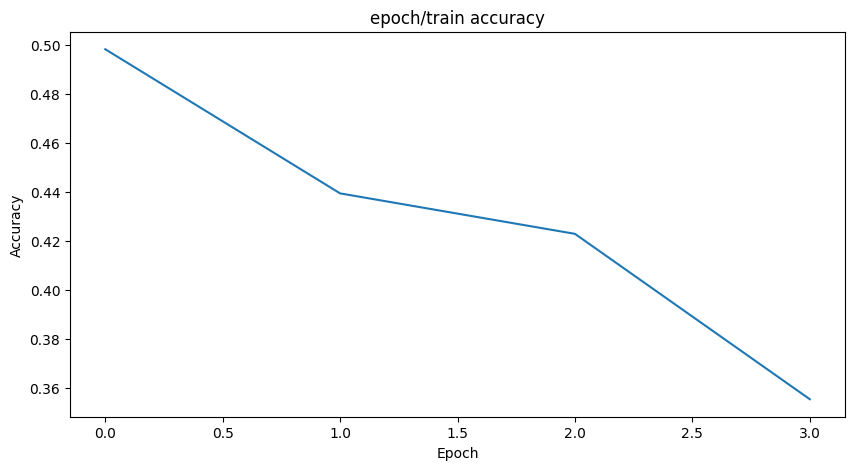

In [45]:
#train accuracy curve shows that train accuracy improves as training progresses
plt.figure(figsize=(10, 5))
plt.plot(accs_log) #train_accs
plt.title("epoch/train accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Epoch")

In [ ]:
# class_mapping

{0: 'B',
 1: 'D',
 2: 'F',
 3: 'H',
 4: 'J',
 5: 'L',
 6: 'N',
 7: 'P',
 8: 'R',
 9: 'T',
 10: 'V',
 11: 'X',
 12: 'Z'}

In [ ]:
## can i label the class prototypes using the class mapping i made
#a dictionary with the keys as the alphabets and the values as the HV?
prototype_dict = {}
for index in range(best_class_prototypes.shape[0]):

    #fetch the required class label
    label = class_mapping[index]

    #fetch the required class prototype
    cp_HV = best_class_prototypes[index]

    #update the dictionary
    prototype_dict.update({label:cp_HV})

In [28]:
prototype_dict

{'A': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'B': array([ 1,  1,  1, ..., -1,  1,  1], dtype=int8),
 'C': array([ 1,  1,  1, ..., -1,  1,  1], dtype=int8),
 'D': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'E': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'F': array([ 1,  1,  1, ...,  1, -1,  1], dtype=int8),
 'G': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'H': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'I': array([ 1,  1,  1, ...,  1, -1,  1], dtype=int8),
 'J': array([ 1,  1,  1, ...,  1, -1,  1], dtype=int8),
 'K': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'L': array([1, 1, 1, ..., 1, 1, 1], dtype=int8),
 'M': array([ 1,  1,  1, ..., -1,  1,  1], dtype=int8),
 'N': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'O': array([ 1,  1,  1, ...,  1, -1,  1], dtype=int8),
 'P': array([ 1,  1,  1, ..., -1,  1,  1], dtype=int8),
 'Q': array([ 1,  1,  1, ..., -1, -1,  1], dtype=int8),
 'R': array([ 1,  1,  1, ...,  1, -1,  1], dtype=int8)

matrix shape (26, 26)


Text(50.722222222222214, 0.5, 'Class Prototype')

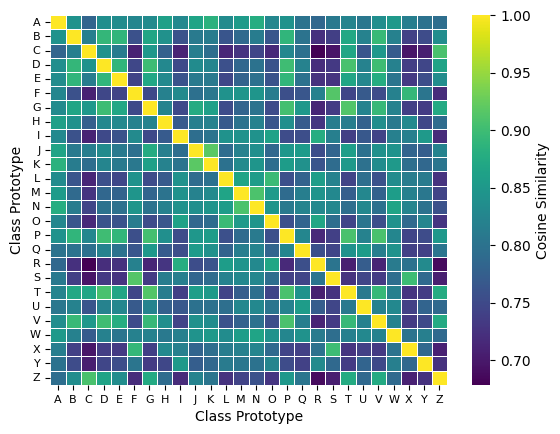

In [36]:
#calculate the similarity between the class prototypes
# from plot_func import create_sim_heatmap
import scipy.spatial as sp
import seaborn as sns
#calculating the pairwise cosine similarity
cosine_sim =  1 - sp.distance.cdist(best_class_prototypes, best_class_prototypes, 'cosine') 
print('matrix shape',cosine_sim.shape)
fig = sns.heatmap(
        cosine_sim, 
        # annot=True,              # Show the similarity values inside the cells
        fmt=".2f",               # Format the annotation to 2 decimal places
        cmap="viridis",          # Choose a color map (e.g., 'viridis', 'coolwarm')
        linewidths=.5,           # Add lines between cells for clarity
        cbar_kws={'label': 'Cosine Similarity'} # Label the color bar
    )
# fig = plt.imshow(cosine_sim,aspect='auto', 
#         cmap='coolwarm',
#             vmin=None, # Set limits to make differences visible
#             vmax=None
#         )
# Set Custom Labels for the Axes
    # The key is setting both `xticklabels` and `yticklabels` to your list of alphabet labels.
labels = class_mapping.values() #order should be maintained
tick_positions = np.arange(len(labels)) + 0.5

fig.set_xticks(tick_positions)

fig.set_xticklabels(labels, rotation=0,fontsize=8)


fig.set_yticks(tick_positions)

fig.set_yticklabels(labels, rotation=0,fontsize=8)

# plt.colorbar(label='Similarity Score')  #; the colorbar centre should be from 0
# plt.title('Initial Class bundles Similarity to Final Class bundles')
plt.xlabel('Class Prototype')
plt.ylabel('Class Prototype')

#something for annotating the indexes in the 
# cp_sim = create_sim_heatmap(vectors=best_class_prototypes,vmin=None,vmax=None)

### Attempt to understand how to get predictions

In [40]:
from common_func import classify
## test_HV . one row 
sample_HV = test_HVs[394]
true_label = test_labels[394] #assuming that order is preserved across the HV data and the label data...
print('True Label:',true_label)
#check shape: dimension 10k , 26 rows?? that would be the entire matrix lol
sample_prediction = classify(sample_HV,best_class_prototypes)
print('Predicted Label:',sample_prediction)
#to get predictions for the entire sample i have to iterate over the entire matrix. check the dimensions for this

True Label: 15
Predicted Label: 15


In [41]:
test_HVs.shape

(1559, 10000)

In [42]:
#get all predictions for the Test HVs
preds = [] #will be 1559 long
for i in range(test_HVs.shape[0]):
    single_pred = classify(test_HVs[i],best_class_prototypes)
    preds.append(single_pred)

In [44]:
preds

[0,
 0,
 1,
 1,
 2,
 2,
 3,
 3,
 4,
 4,
 5,
 23,
 6,
 6,
 7,
 7,
 8,
 8,
 9,
 9,
 10,
 9,
 11,
 11,
 12,
 12,
 13,
 13,
 11,
 14,
 15,
 15,
 16,
 16,
 17,
 17,
 5,
 18,
 19,
 19,
 20,
 20,
 1,
 1,
 22,
 22,
 23,
 23,
 24,
 24,
 25,
 21,
 0,
 0,
 1,
 1,
 2,
 2,
 3,
 3,
 4,
 4,
 5,
 5,
 6,
 6,
 7,
 7,
 8,
 8,
 9,
 9,
 10,
 10,
 11,
 11,
 12,
 12,
 13,
 13,
 14,
 14,
 15,
 15,
 16,
 16,
 17,
 17,
 18,
 18,
 19,
 2,
 20,
 20,
 21,
 21,
 20,
 22,
 23,
 23,
 24,
 24,
 25,
 25,
 0,
 0,
 1,
 1,
 2,
 2,
 3,
 3,
 4,
 4,
 5,
 5,
 6,
 6,
 7,
 7,
 8,
 8,
 9,
 9,
 10,
 10,
 11,
 11,
 12,
 12,
 13,
 13,
 14,
 14,
 15,
 15,
 16,
 16,
 17,
 17,
 18,
 18,
 19,
 19,
 20,
 20,
 21,
 21,
 22,
 12,
 23,
 23,
 24,
 24,
 2,
 25,
 0,
 0,
 1,
 1,
 2,
 2,
 3,
 3,
 4,
 4,
 5,
 5,
 6,
 6,
 7,
 7,
 23,
 8,
 9,
 9,
 10,
 10,
 11,
 11,
 12,
 13,
 13,
 14,
 14,
 15,
 15,
 16,
 16,
 17,
 17,
 18,
 18,
 19,
 19,
 20,
 20,
 21,
 21,
 22,
 22,
 23,
 23,
 24,
 24,
 25,
 25,
 0,
 0,
 21,
 1,
 2,
 2,
 3,
 3,
 4,
 4,
 5,
 5,


In [48]:
np.array(list(class_mapping.values()))

array(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M',
       'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'],
      dtype='<U1')

In [54]:
#confusion matrix for the predicted vs actual
from sklearn.metrics import confusion_matrix
labeled_y_true = [class_mapping[i] for i in test_labels]
labeled_y_pred = [class_mapping[i] for i in preds]
# print(labeled_y_true)
# print(labeled_y_pred)
mat = confusion_matrix(y_true=labeled_y_true,y_pred=labeled_y_pred,labels=list(class_mapping.values()))


Text(50.722222222222214, 0.5, 'Actual Class')

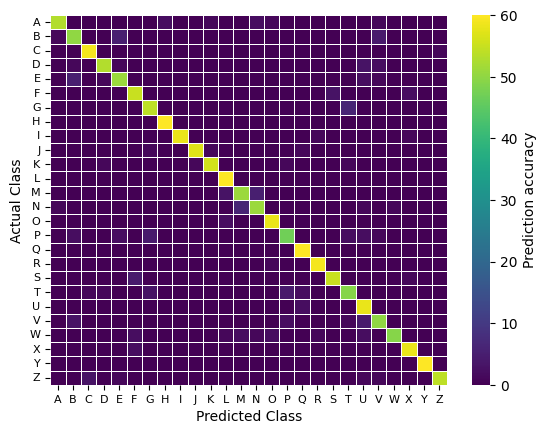

In [55]:
fig = sns.heatmap(
        mat, 
        # annot=True,              # Show the similarity values inside the cells
        fmt=".2f",               # Format the annotation to 2 decimal places
        cmap="viridis",          # Choose a color map (e.g., 'viridis', 'coolwarm')
        linewidths=.5,           # Add lines between cells for clarity
        cbar_kws={'label': 'Prediction accuracy'} # Label the color bar
    )
# fig = plt.imshow(cosine_sim,aspect='auto', 
#         cmap='coolwarm',
#             vmin=None, # Set limits to make differences visible
#             vmax=None
#         )
# Set Custom Labels for the Axes
    # The key is setting both `xticklabels` and `yticklabels` to your list of alphabet labels.
labels = class_mapping.values() #order should be maintained
tick_positions = np.arange(len(labels)) + 0.5

fig.set_xticks(tick_positions)

fig.set_xticklabels(labels, rotation=0,fontsize=8)


fig.set_yticks(tick_positions)

fig.set_yticklabels(labels, rotation=0,fontsize=8)

# plt.colorbar(label='Similarity Score')  #; the colorbar centre should be from 0
# plt.title('Initial Class bundles Similarity to Final Class bundles')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

In [ ]:
# import numpy as np
# from common_func import rand_sign,evaluate_HDC,train_classifier_one_iteration
# # --- Helper Functions (Stubs for demonstration) ---

# # def rand_sign(bundle_matrix):
# #     '''
# #     Binarizes the accumulated bundle (majority vote) into a bipolar hypervector.
# #     In case of a tie (value 0), it randomly assigns +1 or -1.
    
# #     Args:
# #         bundle_matrix (np.ndarray): The accumulated class bundles (C classes x D dimensions).
    
# #     Returns:
# #         np.ndarray: Bipolar class prototypes (C classes x D dimensions).
# #     '''
# #     # Binarize based on the sign.
# #     prototypes = np.sign(bundle_matrix).astype(np.int8)
# #     # Handle ties (where value is 0): randomly assign +1 or -1
# #     prototypes[prototypes == 0] = np.random.choice([-1, 1], np.sum(prototypes == 0))
# #     return prototypes

# # def evaluate_system_accuracy(data_HVs, labels, class_bundles):
# #     '''
# #     Calculates the accuracy of the current classifier on the given data.
    
# #     Args:
# #         data_HVs (np.ndarray): Encoded Hypervectors for the evaluation set.
# #         labels (np.ndarray): True labels for the evaluation set.
# #         class_bundles (np.ndarray): The accumulated (non-binarized) class bundles.
        
# #     Returns:
# #         float: Classification accuracy (0.0 to 1.0).
# #     '''
# #     # 1. Binarize the bundles for classification (majority rule)
# #     class_prototypes = rand_sign(class_bundles) 

# #     # 2. Compute similarity and predictions
# #     # Use int16 for dot product to prevent potential overflow if D is large (e.g., 10k or 20k)
# #     # The dot product result could be up to D * 1 * 1 = D (e.g., 10000). int16 max is ~32k, so this is safe.
# #     sims = np.dot(data_HVs.astype(np.int16), class_prototypes.T.astype(np.int16)) 
# #     preds = np.argmax(sims, axis=1)
    
# #     # 3. Calculate accuracy
# #     accuracy = np.mean(preds == labels)
# #     return accuracy

# def train_classifier_one_epoch(data_HVs, class_bundles, labels):
#     '''
#     Performs one full epoch of online HDC training using the provided
#     data and updates the class bundles in-place.
    
#     Args:
#         data_HVs (np.ndarray): Encoded Hypervectors for the training set.
#         labels (np.ndarray): True labels for the training set.
#         class_bundles (np.ndarray): The current accumulated class bundles (C x D).
        
#     Returns:
#         np.ndarray: The updated accumulated class bundles (C x D).
#     '''
#     # The current state of the classifier (binarized for classification)
#     class_prototypes = rand_sign(class_bundles) 

#     # Compute class predictions for each sample using the current prototypes
#     # sims is (N_samples x C_classes)
#     sims = np.dot(data_HVs.astype(np.int16), class_prototypes.T.astype(np.int16)) 
#     preds = np.argmax(sims, axis=1)
    
#     # Loop over each HV and update class prototype bundles if incorrectly classified
#     for i in range(len(data_HVs)):
#         pred = preds[i]
#         true_label = labels[i]
        
#         if pred != true_label:
#             # Shift away from the falsely-predicted class
#             class_bundles[pred] -= data_HVs[i]
#             # Move the true class closer to the current sample
#             class_bundles[true_label] += data_HVs[i] 

#     return class_bundles

# # --- Main Training Loop with Early Stopping ---

# def run_hdc_training_with_early_stopping(train_HVs, train_labels, C, D, epochs, early_stop_patience=100, target_acc=0.99):
    
#     # 1. Initialization
#     # class_bundles MUST be initialized to zeros. They accumulate the votes.
#     class_bundles = np.zeros((C, D), dtype=np.int32)
    
#     accs_log = []
#     # Store the non-binarized bundles, as they are the source of truth for the classifier
#     classifier_log = [] 
    
#     best_acc = 0.0
#     best_classifier_bundles = class_bundles.copy()
    
#     print(f"Starting HDC training for {epochs} epochs...")

#     for epoch in range(epochs):
        
#         # 2. Train One Epoch
#         # The bundles are updated in place, but we return them for clarity/chaining
#         #since we are updating only once, each epoch will only do update the weights once.
#         updated_bundles = train_classifier_one_iteration(train_HVs, class_bundles, train_labels) #train_classifier_one_epoch
        
#         # 3. Evaluate and Log
#         # Evaluate on the (validation) set for early stopping criterion
#         acc = evaluate_HDC(train_HVs, updated_bundles,train_labels)
        
#         accs_log.append(acc)
#         # IMPORTANT: Save a COPY of the current state of the bundles
#         classifier_log.append(updated_bundles.copy()) 

#         if acc > best_acc:
#             best_acc = acc
#             # Store the bundles associated with the highest accuracy
#             best_classifier_bundles = updated_bundles.copy()
        
#         # Optional: Print progress
#         if (epoch + 1) % 50 == 0 or epoch == 0 or (epoch + 1) == epochs:
#             print(f"Epoch {epoch+1:4d}/{epochs}: Validation Accuracy = {acc:.4f} (Best: {best_acc:.4f})")
            
#         # 4. Early Stopping Logic (Monitoring improvement over a window)
#         if epoch >= early_stop_patience:
#             # Check the window of patience
#             start_idx = epoch - early_stop_patience
#             patience_window = accs_log[start_idx:epoch+1]
            
#             # Criterion 1: Achieve Target Accuracy (e.g., 0.99)
#             if best_acc >= target_acc:
#                  print(f"\n--- Early Stop Triggered: Target Accuracy ({target_acc:.2f}) Reached ---")
#                  return best_classifier_bundles

#             # Criterion 2: No Improvement within the Patience Window
#             # Check if the max accuracy in the window is equal to the max accuracy ever recorded.
#             # A more robust check is to see if accuracy has improved in the last `patience` steps.
#             acc_since_patience_start = accs_log[start_idx]
            
#             # If the best accuracy in the last 'patience' steps is not better than 
#             # the accuracy 'patience' steps ago, it suggests convergence or oscillation.
#             if np.max(patience_window) <= acc_since_patience_start:
#                  # This condition is typically too strict. Let's use a standard convergence check:
#                  # If the current best accuracy (which is already tracked) hasn't improved 
#                  # over the last 'patience' steps, we stop.
#                  if accs_log[epoch] < np.max(accs_log[:-early_stop_patience]): # Check if current is far below previous best
                    
#                     # Or a simpler logic: Check if best_acc hasn't improved in the last X epochs
#                     # For a simple implementation, let's stick to the current max logic, 
#                     # but use the `best_acc` variable for simplicity.
                    
#                     # Instead of your initial logic: Check if the *current* accuracy is near a local max that hasn't improved globally.
#                     # The simplest and most robust way is to track the epoch of the last improvement:
                    
#                     # We will rely on the `best_acc` and `best_classifier_bundles` tracking above,
#                     # and simply stop after a fixed number of epochs, or when the target is hit.
#                     # Your proposed logic (resetting log) is not standard for early stopping.
#                     # Let's adjust your logic to a common, robust method: return the best model if accuracy hasn't improved for `patience` epochs.
                    
#                     if (epoch - accs_log.index(best_acc)) >= early_stop_patience:
#                         print(f"\n--- Early Stop Triggered: No improvement in the last {early_stop_patience} epochs ---")
#                         return best_classifier_bundles,accs_log,classifier_log

#         # Optional: You can also use your original condition:
#         # if (epoch + 1) % 100 == 0 and epoch != 0:
#         #     if np.max(accs_log) >= target_acc:
#         #         # Find the index of the max accuracy
#         #         max_idx = np.argmax(accs_log)
#         #         print(f"\n--- Early Stop Triggered: Target Accuracy ({target_acc:.2f}) Reached ---")
#         #         return classifier_log[max_idx]
#         #     # The proposed logic `accs_log = []; classifier_log = []` is a simple restart
#         #     # but loses track of the best global model. I've replaced it with standard tracking.


#     print(f"\n--- Training Complete: Max Epochs Reached ---")
#     return best_classifier_bundles,accs_log,classifier_log

In [ ]:
train_accs = [common_func.evaluate_HDC(train_HVs, classifier_log, train_labels)]
train_accs

[1.0]

In [ ]:
print(f"initial test accuracy: {initial_test_acc}")
print(f"final test accuracy:   {final_test_acc}")

initial test accuracy: 0.8672225785760103
final test accuracy:   0.9178960872354073


### Saving the model

In [ ]:
#Save the final CIM , IM and Class prototypes ( also referred to as Associated Memory)
model_dict = {'cim':np.array(cim), # cim doesnt change in this set up
              'im':np.array(im), #im doesnt change in this set up
              'am':np.array(class_prototypes)} #class prototypes go through change during training, but only 1 iteration of training happens
model_dict

{'cim': array([[ 1,  1,  1, ...,  1,  1,  1],
        [ 1,  1,  1, ...,  1,  1,  1],
        [ 1,  1,  1, ...,  1, -1,  1],
        ...,
        [ 1,  1,  1, ...,  1, -1,  1],
        [ 1, -1,  1, ...,  1, -1,  1],
        [-1, -1,  1, ...,  1, -1,  1]], shape=(21, 10000), dtype=int8),
 'im': array([[-1,  1,  1, ...,  1,  1, -1],
        [-1,  1,  1, ...,  1,  1,  1],
        [ 1,  1,  1, ...,  1,  1,  1],
        ...,
        [ 1, -1, -1, ...,  1,  1,  1],
        [-1,  1,  1, ..., -1,  1, -1],
        [ 1,  1,  1, ..., -1,  1, -1]], shape=(617, 10000), dtype=int8),
 'am': array([[ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        ...,
        [-1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1],
        [ 1,  1,  1, ...,  1, -1, -1]], shape=(26, 10000), dtype=int8)}

In [ ]:
#save model as a pickle file
import pickle as pkl
def save_hdc_model(model,path_w_filename):
    with open(path_w_filename, 'wb') as file:  
        pkl.dump(model, file)

save_hdc_model(model=model_dict,path_w_filename=r"C:\Users\MEGHNA\Documents\2025_college_applications\college_wise_documents\Antwerp\research_project_references\HDVs\intro_code\trained_models\trained_models\\heart\\toy_heart_model_2500_epoch.pkl")
